# Emotion Classification with Attention (GoEmotions)
Read a short English comment and predict its emotion: **joy, sadness, anger, fear, surprise or disgust**. We also look inside the model and show **which words** drive each prediction, using an attention mechanism.

Four models are trained and compared on the same data: **LSTM, GRU, BiLSTM + Attention** (built from scratch in PyTorch with GloVe embeddings) and a fine-tuned **DistilBERT** (HuggingFace).

**How to run:** set `Accelerator = GPU`, `Internet = On`, then press **Run All**. Everything uses PyTorch only (no TensorFlow), so there is no GPU conflict between frameworks.

| Part | What happens |
|---|---|
| 1-4 | Setup, load data, map 27 emotions to 6, split |
| 5-6 | Text cleaning, GloVe, data loaders |
| 7-8 | Build and train LSTM / GRU / BiLSTM + Attention |
| 9 | Fine-tune DistilBERT |
| 10-13 | Compare models, attention heatmaps, error analysis, demo and save |

## 1) Install, Imports and Settings
`gensim` is only used to load the GloVe vectors. All settings are in one cell.

In [1]:
!pip install -q gensim

In [2]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "0"          

import re, gc, copy, json, random, time
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, f1_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix)



In [3]:
SEED = 42
BATCH = 64
LR = 1e-3
MAX_EPOCHS = 20          # upper limit, early stopping usually ends earlier
PATIENCE = 5            # stop if validation macro F1 does not improve for 3 epochs
HIDDEN = 128             # RNN hidden size (per direction)
ATTN_DIM = 128           # size of the attention layer
DROPOUT = 0.5
MAX_LEN = 50             # max tokens kept per comment

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

device: cuda


## 2) Load the Dataset
**GoEmotions**: about 58k Reddit comments labeled with 27 fine-grained emotions or `neutral`. We use the `simplified` version, which already has train / validation / test splits. A comment can have **more than one** label.

In [4]:
from datasets import load_dataset

ds = load_dataset("google-research-datasets/go_emotions", "simplified")
names = ds["train"].features["labels"].feature.names     # 27 emotions + neutral
print(ds)
print(len(names), "labels")

README.md:   0%|          | 0.00/9.40k [00:00<?, ?B/s]

simplified/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 2.77MB            

simplified/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

simplified/validation-00000-of-00001.par(…): reconstructing file:   0%|          |  0.00B /  350kB            

simplified/validation-00000-of-00001.par(…): downloading bytes:           |  0.00B            

simplified/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  347kB            

simplified/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/43410 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/5426 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/5427 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'labels', 'id'],
        num_rows: 43410
    })
    validation: Dataset({
        features: ['text', 'labels', 'id'],
        num_rows: 5426
    })
    test: Dataset({
        features: ['text', 'labels', 'id'],
        num_rows: 5427
    })
})
28 labels


## 3) Explore the Data
We have 28 labels but the project needs 6, and many comments carry several labels. Let us look at both problems.

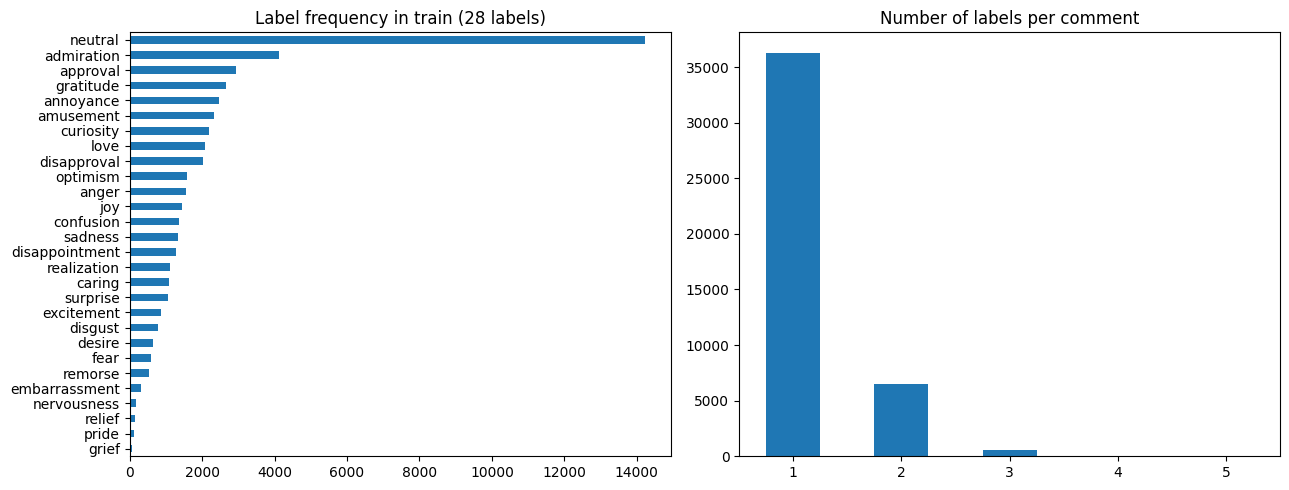

My favourite food is anything I didn't have to cook myself. -> ['neutral']
Now if he does off himself, everyone will think hes having a laugh screwing with people instead of actually dead -> ['neutral']
WHY THE FUCK IS BAYLESS ISOING -> ['anger']
To make her feel threatened -> ['fear']
Dirty Southern Wankers -> ['annoyance']


In [5]:
label_counts = Counter(names[i] for seq in ds["train"]["labels"] for i in seq)
n_labels = Counter(len(seq) for seq in ds["train"]["labels"])

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
pd.Series(label_counts).sort_values().plot(kind="barh", ax=ax[0], title="Label frequency in train (28 labels)")
pd.Series(n_labels).sort_index().plot(kind="bar", ax=ax[1], title="Number of labels per comment", rot=0)
plt.tight_layout(); plt.show()

for i in range(5):
    ex = ds["train"][i]
    print(ex["text"], "->", [names[j] for j in ex["labels"]])

## 4) Map 27 Emotions to 6 and Filter
We use the standard **Ekman** grouping (anger, disgust, fear, joy, sadness, surprise). Every fine-grained emotion goes to one of the six, and `neutral` has no group.

A comment is **kept only if all its labels map to the same single emotion**. Comments that are neutral or that mix different emotions (for example joy + sadness) are dropped, so every remaining comment has one clear label.

train kept 26732 of 43410 | dropped: {'neutral': 14219, 'mixed emotions': 2459}
validation: 3354 | test: 3362


,train,validation,test
y,,,
joy,15216,1941,1863
sadness,2326,266,283
anger,4293,555,572
fear,541,72,80
surprise,3858,459,488
disgust,498,61,76


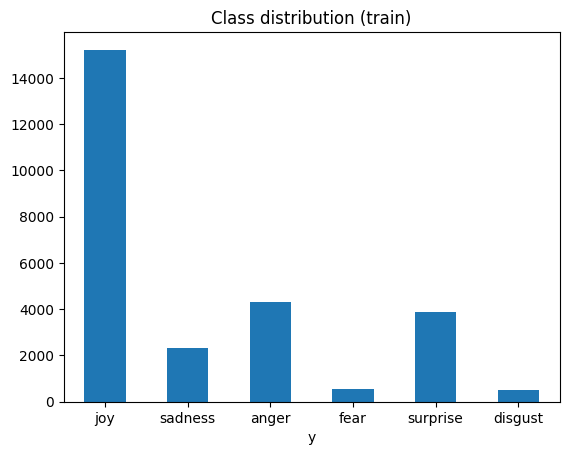

In [6]:
EKMAN = {
    "joy":      ["joy", "amusement", "approval", "excitement", "gratitude", "love", "optimism",
                 "relief", "pride", "admiration", "desire", "caring"],
    "sadness":  ["sadness", "disappointment", "embarrassment", "grief", "remorse"],
    "anger":    ["anger", "annoyance", "disapproval"],
    "fear":     ["fear", "nervousness"],
    "surprise": ["surprise", "realization", "confusion", "curiosity"],
    "disgust":  ["disgust"],
}
EMOTIONS = list(EKMAN)                                   # class order used everywhere
EMO2ID = {e: i for i, e in enumerate(EMOTIONS)}
ID2EMO = {i: e for e, i in EMO2ID.items()}
NUM_CLASSES = len(EMOTIONS)
NAME2EMO = {n: e for e, ns in EKMAN.items() for n in ns}
assert set(NAME2EMO) == set(names) - {"neutral"}          # every fine-grained emotion is mapped

def to_df(split):
    rows, dropped = [], Counter()
    for text, labels in zip(split["text"], split["labels"]):
        label_names = [names[i] for i in labels]
        if "neutral" in label_names:
            dropped["neutral"] += 1
            continue
        emos = {NAME2EMO[n] for n in label_names}
        if len(emos) == 1:
            rows.append((text, EMO2ID[emos.pop()]))
        else:
            dropped["mixed emotions"] += 1
    return pd.DataFrame(rows, columns=["text", "y"]), dropped

train_df, d1 = to_df(ds["train"])
val_df, _ = to_df(ds["validation"])
test_df, _ = to_df(ds["test"])
print(f"train kept {len(train_df)} of {len(ds['train'])} | dropped: {dict(d1)}")
print("validation:", len(val_df), "| test:", len(test_df))

dist = pd.DataFrame({
    "train": train_df["y"].map(ID2EMO).value_counts(),
    "validation": val_df["y"].map(ID2EMO).value_counts(),
    "test": test_df["y"].map(ID2EMO).value_counts(),
}).reindex(EMOTIONS)
display(dist)
dist["train"].plot(kind="bar", rot=0, title="Class distribution (train)"); plt.show()

## 5) Text Cleaning and Class Weights
- Lowercase, unify apostrophes, and split contractions the way GloVe expects (`didn't` becomes `did n't`).
- The dataset hides names and religions as `[NAME]` and `[RELIGION]`; we turn them into plain words.
- **We keep stop words.** Words like `not`, `no` and `never` change the emotion (`not happy`), so removing them would hurt.
- We also keep `!` and `?` because they carry emotion.

DistilBERT uses the original text with its own tokenizer. Classes are imbalanced, so we use **class weights** during training and **macro F1** for evaluation.

In [7]:
def tokenize_text(text):
    t = text.lower().replace("’", "'")
    t = t.replace("[name]", " name ").replace("[religion]", " religion ")
    t = re.sub(r"n't\b", " n't", t)
    t = re.sub(r"'(s|m|re|ve|ll|d)\b", r" '\1", t)
    return re.findall(r"n't|'[a-z]+|[a-z]+|[!?]", t)

for d in (train_df, val_df, test_df):
    d["tokens"] = d["text"].apply(tokenize_text)

train_df = train_df[train_df["tokens"].str.len() > 0].reset_index(drop=True)
val_df = val_df[val_df["tokens"].str.len() > 0].reset_index(drop=True)
test_df = test_df[test_df["tokens"].str.len() > 0].reset_index(drop=True)
print(len(train_df), len(val_df), len(test_df))

lens = train_df["tokens"].str.len()
print(f"tokens per comment: mean {lens.mean():.1f}, 95th percentile {lens.quantile(0.95):.0f}, max {lens.max()}")
print(train_df["text"].iloc[0], "->", train_df["tokens"].iloc[0])

cw = compute_class_weight("balanced", classes=np.arange(NUM_CLASSES), y=train_df["y"].values)
class_w = torch.tensor(cw, dtype=torch.float)
print({ID2EMO[i]: round(float(w), 2) for i, w in enumerate(cw)})

26732 3354 3362
tokens per comment: mean 13.6, 95th percentile 25, max 32
WHY THE FUCK IS BAYLESS ISOING -> ['why', 'the', 'fuck', 'is', 'bayless', 'isoing']
{'joy': 0.29, 'sadness': 1.92, 'anger': 1.04, 'fear': 8.24, 'surprise': 1.15, 'disgust': 8.95}


## 6) GloVe Embeddings and DataLoaders
We download `glove-wiki-gigaword-100` (400,000 words, 100 dimensions) from HuggingFace. GloVe is lowercase, which matches our tokens. The vectors are **frozen**. Words not found in GloVe map to an `UNK` vector.

In [8]:
from huggingface_hub import hf_hub_download
from gensim.models import KeyedVectors

repo = "fse/glove-wiki-gigaword-100"
model_path = hf_hub_download(repo, "glove-wiki-gigaword-100.model")
hf_hub_download(repo, "glove-wiki-gigaword-100.model.vectors.npy")
glove = KeyedVectors.load(model_path)

EMB_DIM = glove.vector_size
PAD, UNK = 0, 1
word2idx = {w: i + 2 for i, w in enumerate(glove.index_to_key)}
emb_matrix = np.vstack([
    np.zeros((1, EMB_DIM)),                          # PAD
    glove.vectors.mean(axis=0, keepdims=True),       # UNK = average vector
    glove.vectors,
]).astype("float32")

all_tokens = [t for toks in train_df["tokens"] for t in toks]
print("GloVe words:", len(glove.key_to_index), "| embedding matrix:", emb_matrix.shape)
print(f"{np.mean([t in word2idx for t in all_tokens]):.1%} of training tokens are found in GloVe")

glove-wiki-gigaword-100.model: reconstructing file:   0%|          |  0.00B / 21.5MB            

glove-wiki-gigaword-100.model: downloading bytes:           |  0.00B            

glove-wiki-gigaword-100.model.vectors.np(…): reconstructing file:   0%|          |  0.00B /  160MB            

glove-wiki-gigaword-100.model.vectors.np(…): downloading bytes:           |  0.00B            

GloVe words: 400000 | embedding matrix: (400002, 100)
99.1% of training tokens are found in GloVe


In [9]:
def encode(tokens):
    return [word2idx.get(t, UNK) for t in tokens[:MAX_LEN]]

class EmoData(Dataset):
    def __init__(self, df):
        self.ids = [encode(t) for t in df["tokens"]]
        self.y = df["y"].tolist()
    def __len__(self):
        return len(self.y)
    def __getitem__(self, i):
        return self.ids[i], self.y[i]

def collate(batch):
    lengths = torch.tensor([len(b[0]) for b in batch])
    words = torch.zeros(len(batch), int(lengths.max()), dtype=torch.long)
    for i, (w, _) in enumerate(batch):
        words[i, :len(w)] = torch.tensor(w)
    return words, lengths, torch.tensor([b[1] for b in batch])

train_loader = DataLoader(EmoData(train_df), batch_size=BATCH, shuffle=True, collate_fn=collate)
val_loader = DataLoader(EmoData(val_df), batch_size=256, shuffle=False, collate_fn=collate)
test_loader = DataLoader(EmoData(test_df), batch_size=256, shuffle=False, collate_fn=collate)
w, l, y = next(iter(train_loader))
print(w.shape, l.shape, y.shape)

torch.Size([64, 32]) torch.Size([64]) torch.Size([64])


## 7) The Classifier (with optional Attention)
One class builds all three from-scratch models:

| Model | RNN | Bidirectional | Attention |
|---|---|---|---|
| LSTM | LSTM | no | no |
| GRU | GRU | no | no |
| BiLSTM + Attention | LSTM | yes | yes |

**Without attention** the sentence is summarized by the last hidden state of the RNN.

**With attention** every word gets a score, the scores are turned into weights that sum to 1 (softmax, ignoring padding), and the sentence representation is the **weighted average of all hidden states**:

`score = v . tanh(W h)`, `weights = softmax(score)`, `sentence = sum(weights * h)`

The weights tell us how much each word mattered, and we plot them later as heatmaps.

In [10]:
class Classifier(nn.Module):
    def __init__(self, emb_matrix, rnn_type, bidirectional, attention):
        super().__init__()
        self.word_emb = nn.Embedding.from_pretrained(torch.tensor(emb_matrix), freeze=False, padding_idx=0)
        rnn_cls = nn.LSTM if rnn_type == "lstm" else nn.GRU
        self.rnn = rnn_cls(emb_matrix.shape[1], HIDDEN, batch_first=True, bidirectional=bidirectional)
        self.rnn_type, self.bi, self.use_attn = rnn_type, bidirectional, attention
        out_dim = HIDDEN * (2 if bidirectional else 1)
        if attention:
            self.attn_proj = nn.Linear(out_dim, ATTN_DIM)
            self.attn_v = nn.Linear(ATTN_DIM, 1, bias=False)
        self.drop = nn.Dropout(DROPOUT)
        self.fc = nn.Linear(out_dim, NUM_CLASSES)

    def forward(self, words, lengths, return_attn=False):
        T = words.size(1)
        x = self.drop(self.word_emb(words))
        packed = nn.utils.rnn.pack_padded_sequence(x, lengths.cpu(), batch_first=True, enforce_sorted=False)
        out, h = self.rnn(packed)
        if self.rnn_type == "lstm":
            h = h[0]                                           # (num_directions, B, HIDDEN)
        out, _ = nn.utils.rnn.pad_packed_sequence(out, batch_first=True, total_length=T)

        alpha = None
        if self.use_attn:
            mask = torch.arange(T, device=words.device)[None, :] < lengths[:, None]
            scores = self.attn_v(torch.tanh(self.attn_proj(out))).squeeze(-1)
            alpha = torch.softmax(scores.masked_fill(~mask, -1e9), dim=-1)      # (B, T)
            rep = (alpha.unsqueeze(-1) * out).sum(dim=1)
        elif self.bi:
            rep = torch.cat([h[-2], h[-1]], dim=-1)
        else:
            rep = h[-1]

        logits = self.fc(self.drop(rep))
        return (logits, alpha) if return_attn else logits

m = Classifier(emb_matrix, "lstm", True, True)
print("trainable parameters:", sum(p.numel() for p in m.parameters() if p.requires_grad))
del m

trainable parameters: 40270286


## 8) Training, Evaluation and the Three From-Scratch Models
- Every epoch we measure **macro F1 on the validation set**, keep the best weights, and stop early if it does not improve for `PATIENCE` epochs.
- The best weights are evaluated **once** on the test set. For each model we print per-class precision / recall / F1 and draw the confusion matrix.

In [11]:
results, per_class_f1, preds_store, histories = {}, {}, {}, {}

@torch.no_grad()
def predict_loader(model, loader):
    model.eval()
    ys, ps = [], []
    for words, lengths, y in loader:
        logits = model(words.to(device), lengths.to(device))
        ps += logits.argmax(-1).cpu().tolist()
        ys += y.tolist()
    return ys, ps

def record(name, y_true, y_pred):
    p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    results[name] = {"Accuracy": accuracy_score(y_true, y_pred), "Precision": p, "Recall": r, "F1": f1}
    f1_each = precision_recall_fscore_support(y_true, y_pred, labels=range(NUM_CLASSES), zero_division=0)[2]
    per_class_f1[name] = dict(zip(EMOTIONS, f1_each))
    preds_store[name] = (y_true, y_pred)
    print(f"===== {name} =====")
    print(classification_report(y_true, y_pred, target_names=EMOTIONS, digits=3, zero_division=0))
    cm = confusion_matrix(y_true, y_pred, normalize="true")
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", xticklabels=EMOTIONS, yticklabels=EMOTIONS)
    plt.title(f"Confusion matrix - {name}"); plt.xlabel("Predicted"); plt.ylabel("True"); plt.tight_layout(); plt.show()

def run_model(name, rnn_type, bidirectional, attention, keep=False):
    print(f"\n#################### {name} ####################")
    model = Classifier(emb_matrix, rnn_type, bidirectional, attention).to(device)
    opt = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=LR)
    loss_fn = nn.CrossEntropyLoss(weight=class_w.to(device))
    best_f1, best_state, bad, history = -1.0, None, 0, []

    for epoch in range(1, MAX_EPOCHS + 1):
        start = time.time()
        model.train()
        total = 0.0
        for words, lengths, y in train_loader:
            words, lengths, y = words.to(device), lengths.to(device), y.to(device)
            opt.zero_grad()
            loss = loss_fn(model(words, lengths), y)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            opt.step()
            total += loss.item()

        yv, pv = predict_loader(model, val_loader)
        val_f1 = f1_score(yv, pv, average="macro")
        history.append(val_f1)
        print(f"epoch {epoch:2d} | train loss {total / len(train_loader):.4f} | val macro F1 {val_f1:.4f} | {time.time() - start:.0f}s")

        if val_f1 > best_f1:
            best_f1, bad = val_f1, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            bad += 1
            if bad >= PATIENCE:
                print("early stopping")
                break

    model.load_state_dict(best_state)
    y_true, y_pred = predict_loader(model, test_loader)
    record(name, y_true, y_pred)
    histories[name] = history

    if keep:
        return model
    del model, opt
    gc.collect(); torch.cuda.empty_cache()

### 8.1 LSTM


#################### LSTM ####################
epoch  1 | train loss 1.6122 | val macro F1 0.4170 | 13s
epoch  2 | train loss 1.2676 | val macro F1 0.5752 | 9s
epoch  3 | train loss 1.0454 | val macro F1 0.6062 | 9s
epoch  4 | train loss 0.9142 | val macro F1 0.6435 | 9s
epoch  5 | train loss 0.8371 | val macro F1 0.6354 | 9s
epoch  6 | train loss 0.7594 | val macro F1 0.6249 | 9s
epoch  7 | train loss 0.7149 | val macro F1 0.6496 | 9s
epoch  8 | train loss 0.6630 | val macro F1 0.6415 | 9s
epoch  9 | train loss 0.6128 | val macro F1 0.6367 | 9s
epoch 10 | train loss 0.5868 | val macro F1 0.6267 | 9s
epoch 11 | train loss 0.5450 | val macro F1 0.6316 | 9s
epoch 12 | train loss 0.5132 | val macro F1 0.6309 | 9s
early stopping
===== LSTM =====
              precision    recall  f1-score   support

         joy      0.923     0.781     0.846      1863
     sadness      0.635     0.622     0.629       283
       anger      0.569     0.659     0.611       572
        fear      0.500     0.

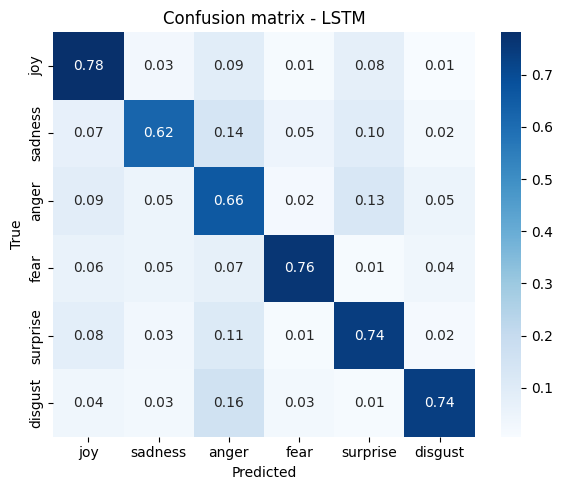

In [12]:
run_model("LSTM", "lstm", bidirectional=False, attention=False)

### 8.2 GRU


#################### GRU ####################
epoch  1 | train loss 1.5917 | val macro F1 0.4564 | 9s
epoch  2 | train loss 1.1642 | val macro F1 0.5725 | 9s
epoch  3 | train loss 0.9706 | val macro F1 0.6257 | 9s
epoch  4 | train loss 0.8691 | val macro F1 0.6276 | 9s
epoch  5 | train loss 0.7993 | val macro F1 0.6184 | 9s
epoch  6 | train loss 0.7542 | val macro F1 0.6317 | 9s
epoch  7 | train loss 0.6920 | val macro F1 0.5920 | 9s
epoch  8 | train loss 0.6538 | val macro F1 0.6320 | 9s
epoch  9 | train loss 0.6104 | val macro F1 0.6289 | 9s
epoch 10 | train loss 0.5728 | val macro F1 0.6326 | 9s
epoch 11 | train loss 0.5341 | val macro F1 0.6322 | 9s
epoch 12 | train loss 0.5070 | val macro F1 0.6292 | 9s
epoch 13 | train loss 0.4753 | val macro F1 0.6364 | 9s
epoch 14 | train loss 0.4409 | val macro F1 0.6449 | 9s
epoch 15 | train loss 0.4170 | val macro F1 0.6161 | 9s
epoch 16 | train loss 0.3999 | val macro F1 0.6322 | 9s
epoch 17 | train loss 0.3851 | val macro F1 0.6219 | 9s
e

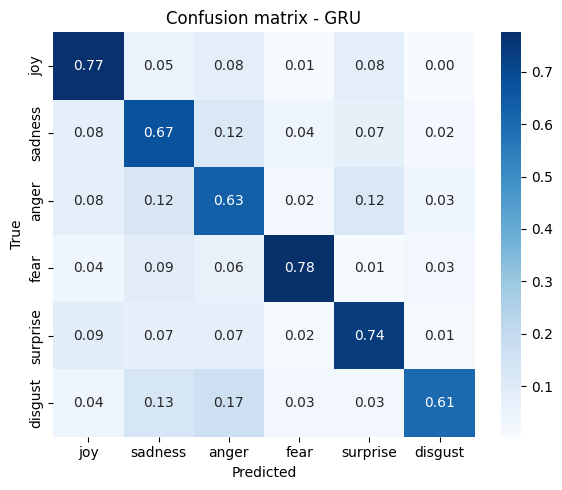

In [13]:
run_model("GRU", "gru", bidirectional=False, attention=False)

### 8.3 BiLSTM + Attention
We keep this trained model in memory because we need it for the attention heatmaps later.


#################### BiLSTM+Attention ####################
epoch  1 | train loss 1.4161 | val macro F1 0.5567 | 11s
epoch  2 | train loss 1.0323 | val macro F1 0.6171 | 11s
epoch  3 | train loss 0.9283 | val macro F1 0.6218 | 11s
epoch  4 | train loss 0.8543 | val macro F1 0.6126 | 11s
epoch  5 | train loss 0.7940 | val macro F1 0.6357 | 11s
epoch  6 | train loss 0.7386 | val macro F1 0.6095 | 11s
epoch  7 | train loss 0.6871 | val macro F1 0.6483 | 11s
epoch  8 | train loss 0.6533 | val macro F1 0.6175 | 11s
epoch  9 | train loss 0.5936 | val macro F1 0.6433 | 11s
epoch 10 | train loss 0.5606 | val macro F1 0.6414 | 11s
epoch 11 | train loss 0.5265 | val macro F1 0.6226 | 11s
epoch 12 | train loss 0.4944 | val macro F1 0.6248 | 11s
early stopping
===== BiLSTM+Attention =====
              precision    recall  f1-score   support

         joy      0.939     0.756     0.838      1863
     sadness      0.572     0.661     0.613       283
       anger      0.554     0.691     0.615      

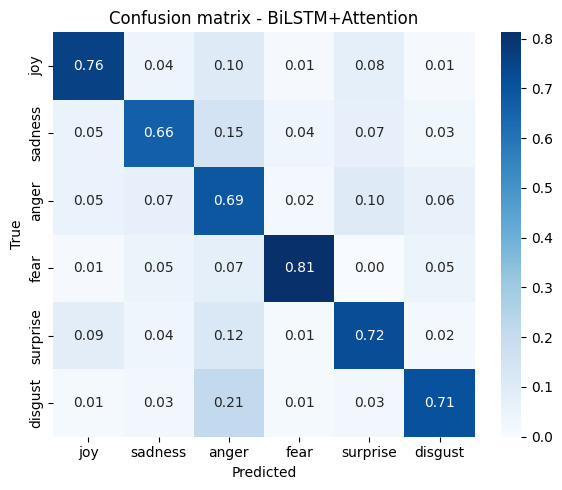

In [14]:
attn_model = run_model("BiLSTM+Attention", "lstm", bidirectional=True, attention=True, keep=True)

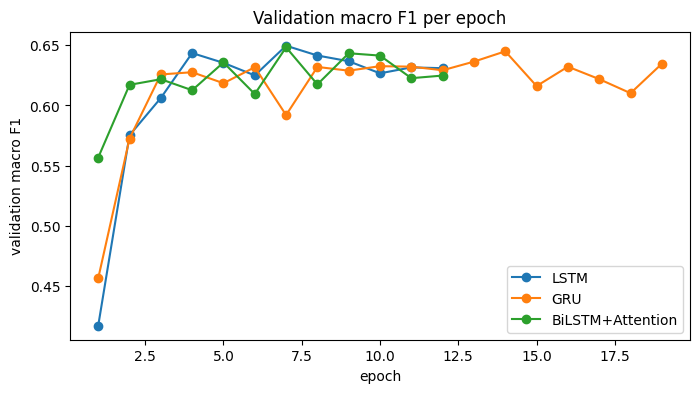

In [15]:
plt.figure(figsize=(8, 4))
for name, h in histories.items():
    plt.plot(range(1, len(h) + 1), h, marker="o", label=name)
plt.xlabel("epoch"); plt.ylabel("validation macro F1"); plt.title("Validation macro F1 per epoch"); plt.legend(); plt.show()

## 9) Fine-tune DistilBERT (HuggingFace)
- Model: `distilbert-base-uncased` with a 6-class classification head, trained with the `Trainer` API.
- It reads the **original text** (not our cleaned tokens) with its own tokenizer.
- The loss is **class-weighted** like the other models, and the best epoch (by validation macro F1) is kept.

In [16]:
from datasets import Dataset
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          DataCollatorWithPadding, TrainingArguments, Trainer)

BERT_NAME = "distilbert-base-uncased"
tok = AutoTokenizer.from_pretrained(BERT_NAME)

def to_hf(df):
    d = Dataset.from_dict({"text": df["text"].tolist(), "label": df["y"].tolist()})
    return d.map(lambda b: tok(b["text"], truncation=True, max_length=64), batched=True, remove_columns=["text"])

train_ds, val_ds, test_ds = to_hf(train_df), to_hf(val_df), to_hf(test_df)
print(train_ds)

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/26732 [00:00<?, ? examples/s]

Map:   0%|          | 0/3354 [00:00<?, ? examples/s]

Map:   0%|          | 0/3362 [00:00<?, ? examples/s]

Dataset({
    features: ['label', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 26732
})


In [17]:
class WeightedTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        loss = nn.CrossEntropyLoss(weight=class_w.to(outputs.logits.device))(outputs.logits, labels)
        return (loss, outputs) if return_outputs else loss

def compute_metrics(p):
    logits, labels = p
    preds = logits.argmax(-1)
    return {"accuracy": accuracy_score(labels, preds), "f1": f1_score(labels, preds, average="macro")}

bert = AutoModelForSequenceClassification.from_pretrained(
    BERT_NAME, num_labels=NUM_CLASSES, id2label=ID2EMO, label2id=EMO2ID)

args = TrainingArguments(
    output_dir="/kaggle/working/emotion_out",
    num_train_epochs=4,
    learning_rate=3e-5,
    per_device_train_batch_size=32,
    per_device_eval_batch_size=128,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=1,
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    fp16=torch.cuda.is_available(),
    report_to="none",
    seed=SEED,
)

trainer = WeightedTrainer(
    model=bert, args=args,
    train_dataset=train_ds, eval_dataset=val_ds,
    data_collator=DataCollatorWithPadding(tok),
    compute_metrics=compute_metrics,
)
trainer.train()

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,F1
1,1.033673,0.719259,0.781753,0.666311
2,0.608148,0.748779,0.788014,0.671543
3,0.405109,0.864730,0.806500,0.692279
4,0.275609,0.964277,0.810078,0.695568


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=3344, training_loss=0.5630492319901024, metrics={'train_runtime': 149.9213, 'train_samples_per_second': 713.228, 'train_steps_per_second': 22.305, 'total_flos': 991096559959104.0, 'train_loss': 0.5630492319901024, 'epoch': 4.0})

===== DistilBERT =====
              precision    recall  f1-score   support

         joy      0.932     0.875     0.903      1863
     sadness      0.647     0.668     0.657       283
       anger      0.686     0.703     0.694       572
        fear      0.667     0.800     0.727        80
    surprise      0.695     0.766     0.729       488
     disgust      0.460     0.605     0.523        76

    accuracy                          0.805      3362
   macro avg      0.681     0.736     0.706      3362
weighted avg      0.815     0.805     0.809      3362



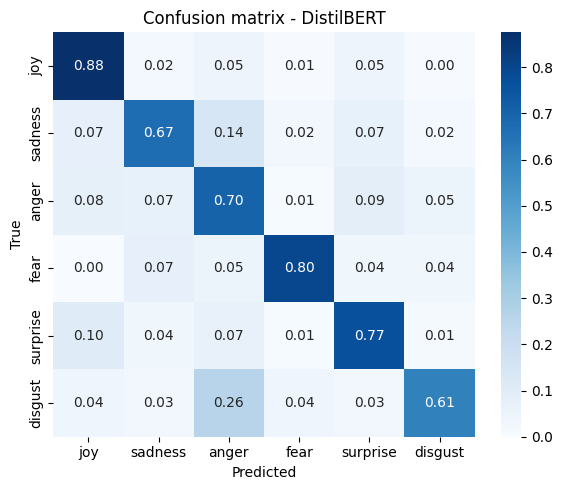

In [18]:
out = trainer.predict(test_ds)
record("DistilBERT", out.label_ids.tolist(), out.predictions.argmax(-1).tolist())

## 10) Compare the 4 Models
Scores on the **test set**. Precision, recall and F1 are macro averages (every emotion counts the same). **Macro F1** is the main metric because the classes are imbalanced.

,Accuracy,Precision,Recall,F1,joy F1,sadness F1,anger F1,fear F1,surprise F1,disgust F1
DistilBERT,0.8049,0.6812,0.7363,0.7056,0.9029,0.6574,0.6943,0.7273,0.7290,0.5227
LSTM,0.7394,0.6173,0.7168,0.6552,0.8462,0.6286,0.6105,0.6040,0.6588,0.5833
BiLSTM+Attention,0.7323,0.6082,0.7256,0.6522,0.8376,0.6131,0.6148,0.6599,0.6635,0.5243
GRU,0.7296,0.6118,0.6989,0.6461,0.8397,0.5496,0.6166,0.6458,0.6606,0.5644


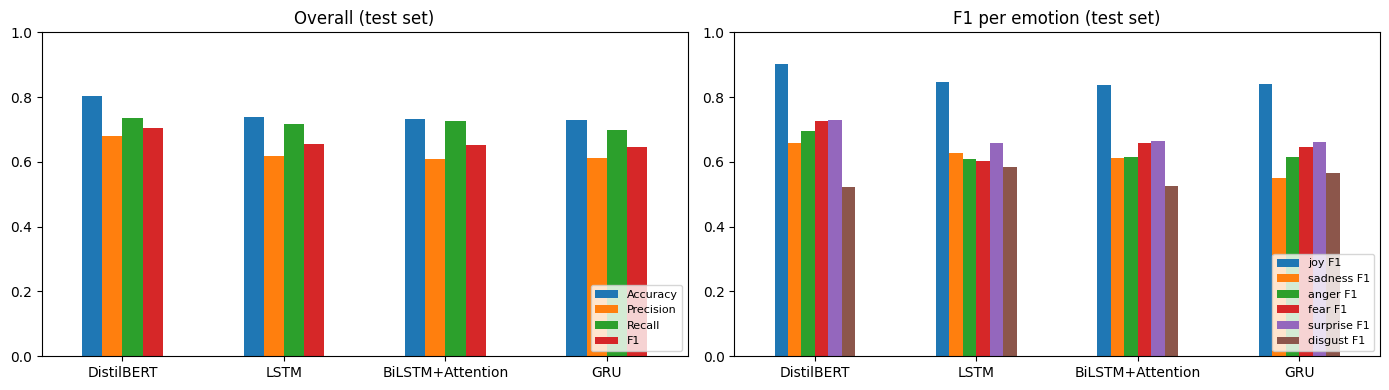

Best model: DistilBERT


In [19]:
rows = {m: {**results[m], **{f"{e} F1": per_class_f1[m][e] for e in EMOTIONS}} for m in results}
res_df = pd.DataFrame(rows).T.round(4).sort_values("F1", ascending=False)
display(res_df)

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
res_df[["Accuracy", "Precision", "Recall", "F1"]].plot(kind="bar", ax=ax[0], title="Overall (test set)")
res_df[[f"{e} F1" for e in EMOTIONS]].plot(kind="bar", ax=ax[1], title="F1 per emotion (test set)")
for a in ax:
    a.set_ylim(0, 1); a.tick_params(axis="x", rotation=0); a.legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()
print("Best model:", res_df.index[0])

## 11) Attention Heatmaps
For each sentence we show the attention weight the **BiLSTM + Attention** model gives to every word (darker red = more attention) and the emotion it predicts.

Keep in mind that attention weights are a useful hint about what the model looked at, but they are **not a proof** of why it made a decision.

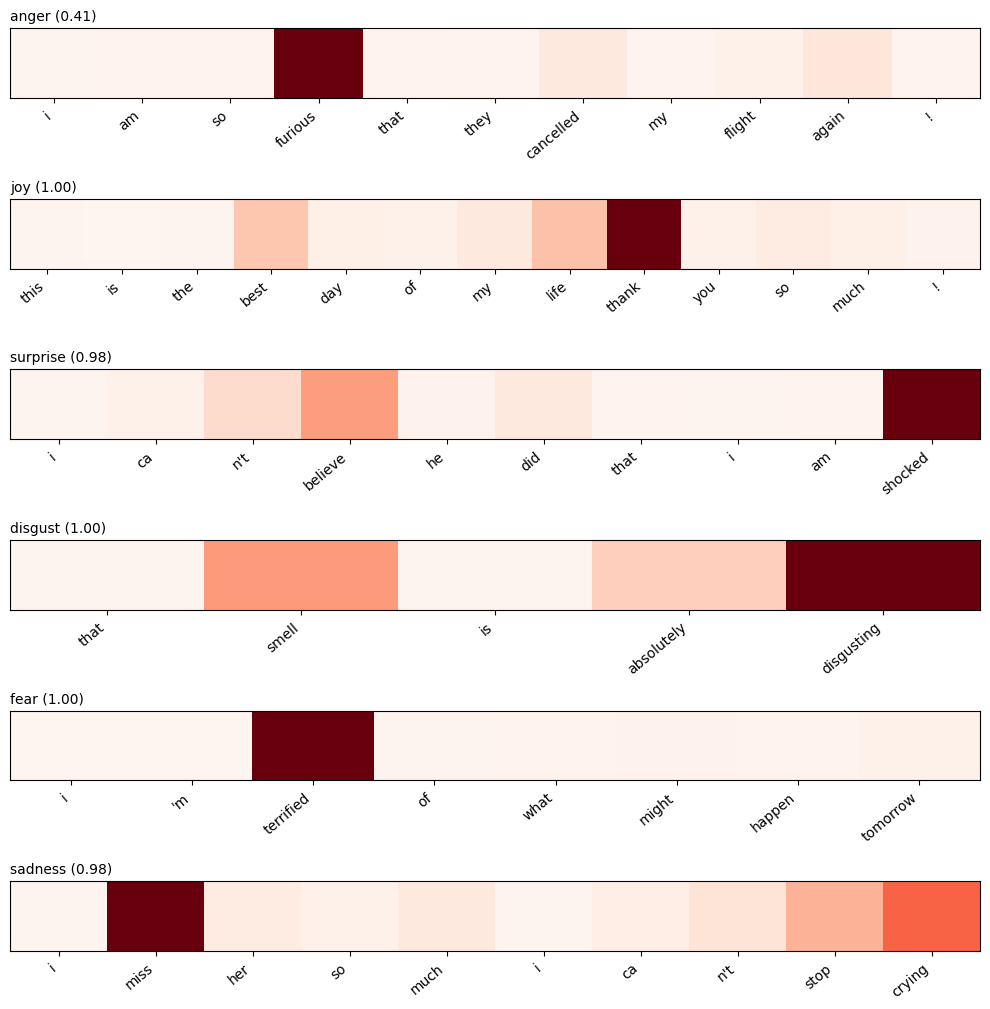

In [20]:
@torch.no_grad()
def explain(model, text):
    toks = tokenize_text(text)[:MAX_LEN]
    if not toks:
        return toks, None, None
    ids = torch.tensor([encode(toks)], device=device)
    lengths = torch.tensor([len(toks)], device=device)
    model.eval()
    logits, alpha = model(ids, lengths, return_attn=True)
    return toks, alpha[0].cpu().numpy(), torch.softmax(logits, -1)[0].cpu().numpy()

def plot_attention(model, texts):
    fig, axes = plt.subplots(len(texts), 1, figsize=(10, 1.7 * len(texts)))
    axes = np.atleast_1d(axes)
    for ax, text in zip(axes, texts):
        toks, alpha, probs = explain(model, text)
        if alpha is None:
            continue
        ax.imshow(alpha[None, :], aspect="auto", cmap="Reds", vmin=0, vmax=max(float(alpha.max()), 1e-6))
        ax.set_xticks(range(len(toks))); ax.set_xticklabels(toks, rotation=40, ha="right")
        ax.set_yticks([])
        ax.set_title(f"{ID2EMO[int(probs.argmax())]} ({probs.max():.2f})", loc="left", fontsize=10)
    plt.tight_layout(); plt.show()

custom = [
    "I am so furious that they cancelled my flight again!",
    "This is the best day of my life, thank you so much!",
    "I can't believe he did that, I am shocked.",
    "That smell is absolutely disgusting.",
    "I'm terrified of what might happen tomorrow.",
    "I miss her so much, I can't stop crying.",
]
plot_attention(attn_model, custom)

true: joy       | Parents drugging their kids to prove a point. I love it.
true: surprise  | Do you have any tinder picture or bio advice? I have no selfies or mirror pics but still not doing very well
true: joy       | [NAME], with his 8th appearance he's the most veteran player there
true: joy       | Thank you kindly! I'll update my resume!
true: joy       | Before all of the BS lol


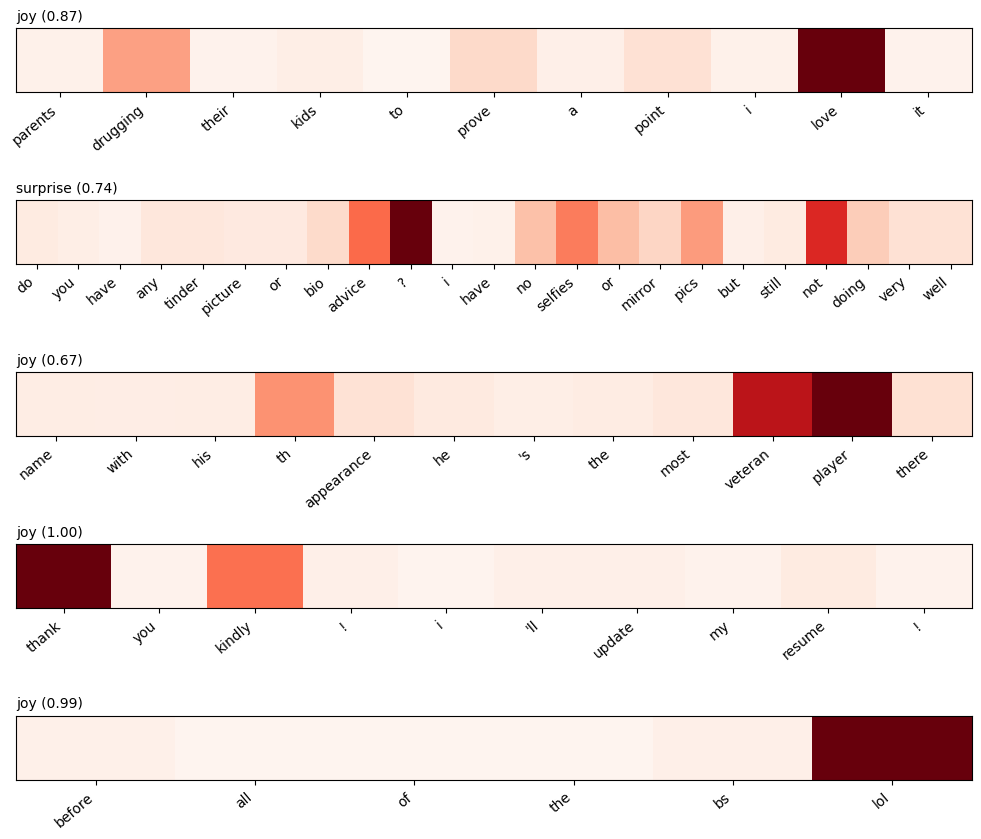

In [21]:
sample = test_df.sample(5, random_state=SEED)
for t, y in zip(sample["text"], sample["y"]):
    print(f"true: {ID2EMO[y]:9} | {t}")
plot_attention(attn_model, sample["text"].tolist())

## 12) Error Analysis
Which emotions get confused with each other, and what do the mistakes look like? This uses the best model by macro F1.

In [22]:
best = res_df.index[0]
yt, yp = (np.array(a) for a in preds_store[best])
cm = confusion_matrix(yt, yp, labels=range(NUM_CLASSES))
pairs = [(EMOTIONS[i], EMOTIONS[j], int(cm[i, j])) for i in range(NUM_CLASSES) for j in range(NUM_CLASSES) if i != j]

print(f"Most frequent confusions ({best}):")
for t, p, c in sorted(pairs, key=lambda x: -x[2])[:8]:
    print(f"  true {t:9} -> predicted {p:9} {c} comments")

print("\nSome mistakes:")
rng = np.random.RandomState(SEED)
for i in rng.choice(np.where(yt != yp)[0], size=8, replace=False):
    print(f"  true {ID2EMO[yt[i]]:9} | predicted {ID2EMO[yp[i]]:9} | {test_df['text'].iloc[i]}")

Most frequent confusions (DistilBERT):
  true joy       -> predicted surprise  89 comments
  true joy       -> predicted anger     86 comments
  true surprise  -> predicted joy       51 comments
  true anger     -> predicted surprise  50 comments
  true anger     -> predicted joy       44 comments
  true sadness   -> predicted anger     41 comments
  true anger     -> predicted sadness   40 comments
  true joy       -> predicted sadness   37 comments

Some mistakes:
  true sadness   | predicted anger     | Your TLDR sucks
  true joy       | predicted surprise  | Wow, so he was pulling his own little mini [NAME] scam. Explains why he couldn't use your reporting tool.
  true anger     | predicted sadness   | Those fingers disturb me the most
  true joy       | predicted surprise  | That was my first thought too 😂
  true joy       | predicted anger     | You ain't wrong
  true disgust   | predicted anger     | cause he constantly hates on [NAME] for no reason other than Petry having the p

## 13) Demo and Save the Model
A quick check with the fine-tuned DistilBERT: the probability of each of the 6 emotions. This is the output the web app will show as a bar chart.

The model is saved in `/kaggle/working/emotion_model` and will be uploaded to the Hugging Face Hub for the app.

In [23]:
from transformers import pipeline

clf = pipeline("text-classification", model=trainer.model, tokenizer=tok, top_k=None,
               device=0 if torch.cuda.is_available() else -1)

for s in ["I can't believe they actually did it, this is amazing!",
          "Leave me alone, I am sick of your lies.",
          "I am so scared of the exam tomorrow.",
          "That is the most disgusting thing I have ever seen.",
          "I miss my old friends so much."]:
    res = clf(s)
    res = res[0] if isinstance(res[0], list) else res
    print(s)
    print("  ", [(d["label"], round(d["score"], 2)) for d in sorted(res, key=lambda d: -d["score"])])

I can't believe they actually did it, this is amazing!
   [('joy', 0.94), ('surprise', 0.05), ('anger', 0.0), ('fear', 0.0), ('sadness', 0.0), ('disgust', 0.0)]
Leave me alone, I am sick of your lies.
   [('sadness', 0.89), ('anger', 0.1), ('joy', 0.01), ('disgust', 0.0), ('surprise', 0.0), ('fear', 0.0)]
I am so scared of the exam tomorrow.
   [('fear', 1.0), ('anger', 0.0), ('sadness', 0.0), ('joy', 0.0), ('disgust', 0.0), ('surprise', 0.0)]
That is the most disgusting thing I have ever seen.
   [('disgust', 0.99), ('anger', 0.0), ('sadness', 0.0), ('joy', 0.0), ('fear', 0.0), ('surprise', 0.0)]
I miss my old friends so much.
   [('sadness', 0.99), ('joy', 0.0), ('anger', 0.0), ('fear', 0.0), ('surprise', 0.0), ('disgust', 0.0)]


In [24]:
trainer.save_model("/kaggle/working/emotion_model")
tok.save_pretrained("/kaggle/working/emotion_model")
res_df.to_csv("/kaggle/working/emotion_results.csv")
print(os.listdir("/kaggle/working/emotion_model"))

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

['model.safetensors', 'training_args.bin', 'config.json', 'tokenizer_config.json', 'tokenizer.json']
